# SVM trên dữ liệu Breast Cancer với hai đặc trưng đầu tiên (mục 7.2)

Ranh giới của kernel tuyến tính và kernel RBF, các vector hỗ trợ

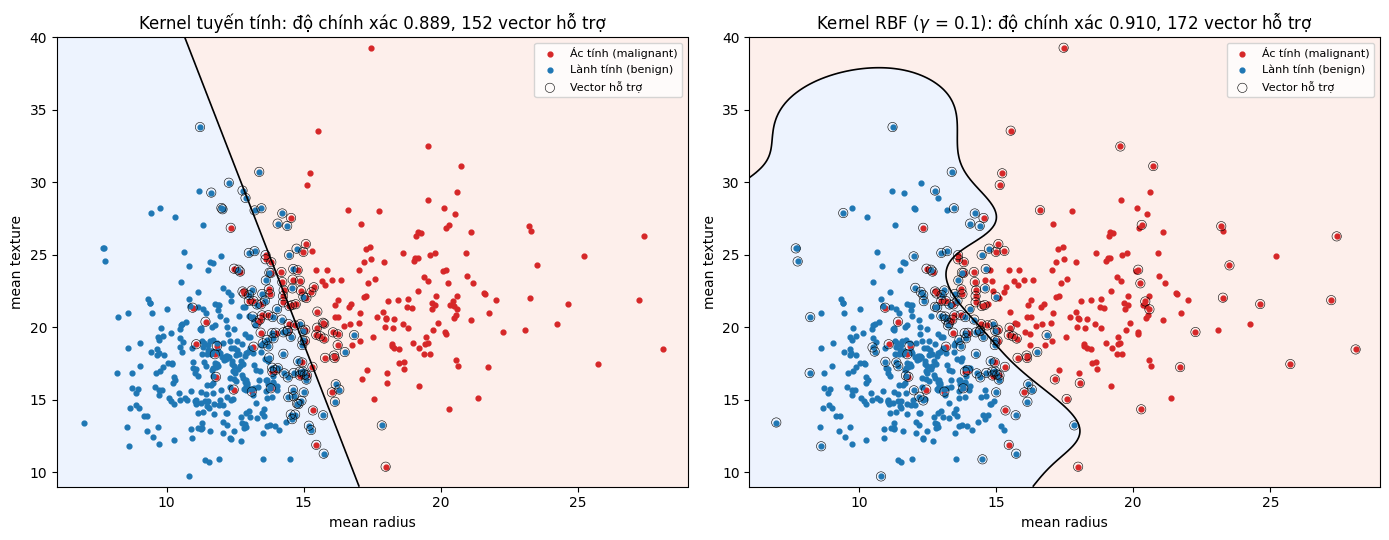

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.svm import SVC

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

cancer = load_breast_cancer()
X = cancer.data[:, :2]                      # mean radius, mean texture
y = cancer.target                           # 0 = ác tính, 1 = lành tính

xx, yy = np.meshgrid(np.linspace(6, 29, 300), np.linspace(9, 40, 300))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, model) in zip(axes, [('Kernel tuyến tính', SVC(kernel='linear', C=1)),
                                    ('Kernel RBF ($\\gamma$ = 0.1)', SVC(kernel='rbf', C=1, gamma=0.1))]):
    model.fit(X, y)
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.15, cmap='coolwarm_r')
    ax.contour(xx, yy, zz, levels=[0], colors='k', linewidths=1.2)
    for label, color, text in [(0, '#D62728', 'Ác tính (malignant)'), (1, '#1F77B4', 'Lành tính (benign)')]:
        ax.scatter(X[y == label, 0], X[y == label, 1], s=12, color=color, label=text)
    ax.scatter(*model.support_vectors_.T, s=45, facecolors='none', edgecolors='k', linewidths=0.4, label='Vector hỗ trợ')
    ax.set_xlabel('mean radius'); ax.set_ylabel('mean texture')
    ax.set_title('%s: độ chính xác %.3f, %d vector hỗ trợ' % (name, model.score(X, y), len(model.support_)))
    ax.legend(fontsize=8, loc='upper right')
fig.tight_layout()
fig.savefig(IMAGES / 'breast_cancer_svm.png', dpi=150)